# Exercise 14: PCA-based Classification - Solution
### (010000) Machine Learning - Spring 2026
### Prof. Cheol Jeong, Sejong University

## Task 1: Load the Wine dataset.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

wine = load_wine(as_frame=True)
X = wine.data
y = wine.target
feature_names = wine.feature_names
class_names   = list(wine.target_names)

print('Shape of X:', X.shape)
print('Classes   :', class_names)
print('Class counts:')
print(pd.Series(y).value_counts().sort_index())

Shape of X: (178, 13)
Classes   : [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Class counts:
target
0    59
1    71
2    48
Name: count, dtype: int64


## Task 2: Train / test split.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2026, stratify=y
)

print('X_train shape:', X_train.shape)
print('X_test  shape:', X_test.shape)

X_train shape: (124, 13)
X_test  shape: (54, 13)


## Task 3: Scree plot and cumulative explained variance.

PCA is fit on the standardized **training set** only.

Components to reach 90% variance: 8
Components to reach 95% variance: 10


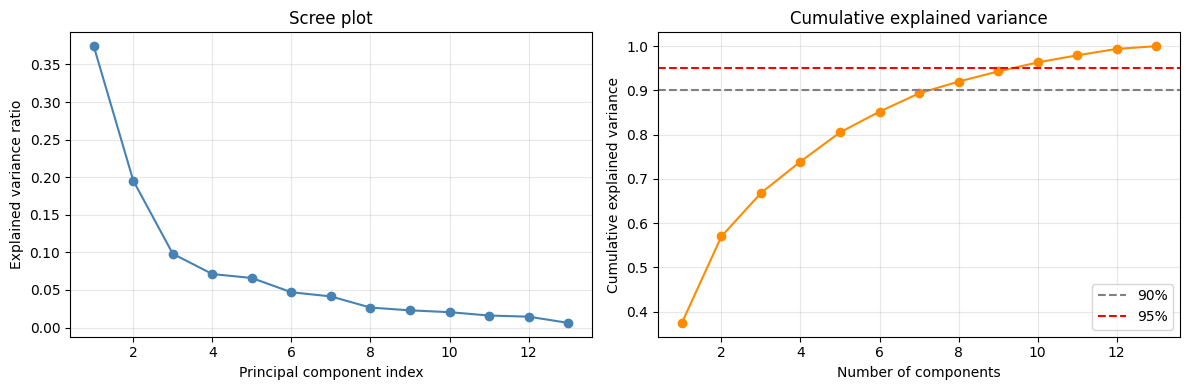

In [ ]:
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)

pca_full = PCA().fit(X_train_std)
evr     = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)

M_90 = int(np.argmax(cum_evr >= 0.90) + 1)
M_95 = int(np.argmax(cum_evr >= 0.95) + 1)
print(f'Components to reach 90% variance: {M_90}')
print(f'Components to reach 95% variance: {M_95}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, len(evr) + 1), evr, 'o-', color='steelblue')
axes[0].set_xlabel('Principal component index')
axes[0].set_ylabel('Explained variance ratio')
axes[0].set_title('Scree plot')
axes[0].grid(alpha=0.3)

axes[1].plot(range(1, len(cum_evr) + 1), cum_evr, 'o-', color='darkorange')
axes[1].axhline(0.90, color='gray', linestyle='--', label='90%')
axes[1].axhline(0.95, color='red',  linestyle='--', label='95%')
axes[1].set_xlabel('Number of components')
axes[1].set_ylabel('Cumulative explained variance')
axes[1].set_title('Cumulative explained variance')
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()

## Task 4: 2D PCA visualization.

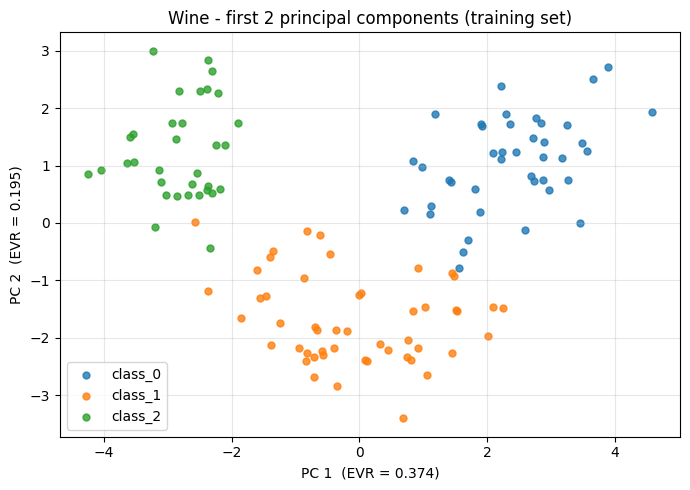

In [ ]:
pca2 = PCA(n_components=2)
X_train_2d = pca2.fit_transform(X_train_std)

plt.figure(figsize=(7, 5))
for cls, name, color in zip([0, 1, 2], class_names, ['tab:blue', 'tab:orange', 'tab:green']):
    pts = X_train_2d[y_train == cls]
    plt.scatter(pts[:, 0], pts[:, 1], label=name, alpha=0.8, s=25, c=color)
plt.xlabel(f'PC 1  (EVR = {pca2.explained_variance_ratio_[0]:.3f})')
plt.ylabel(f'PC 2  (EVR = {pca2.explained_variance_ratio_[1]:.3f})')
plt.title('Wine - first 2 principal components (training set)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Task 5: Pipeline (StandardScaler -> PCA -> LogisticRegression) with M = 2.

In [ ]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca',    PCA(n_components=2)),
    ('clf',    LogisticRegression(max_iter=1000, random_state=2026))
])
pipe.fit(X_train, y_train)

print('Pipeline (M = 2) training accuracy:', round(pipe.score(X_train, y_train), 4))
print('Pipeline (M = 2) test     accuracy:', round(pipe.score(X_test,  y_test ), 4))

Pipeline (M = 2) training accuracy: 0.9758
Pipeline (M = 2) test     accuracy: 0.9444


## Task 6: Confusion matrix and classification report.

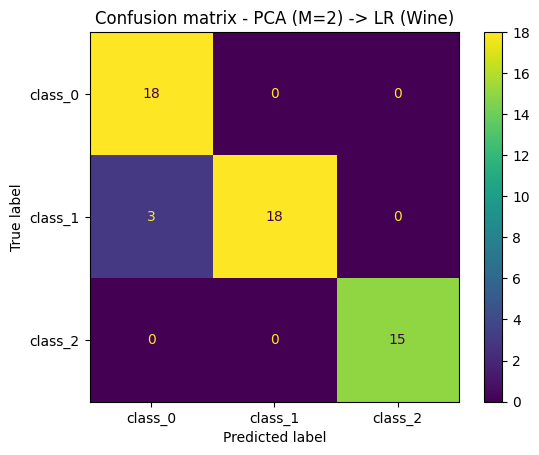

              precision    recall  f1-score   support

     class_0       0.86      1.00      0.92        18
     class_1       1.00      0.86      0.92        21
     class_2       1.00      1.00      1.00        15

    accuracy                           0.94        54
   macro avg       0.95      0.95      0.95        54
weighted avg       0.95      0.94      0.94        54



In [ ]:
y_pred = grid.best_estimator_.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot()
plt.title(f'Confusion matrix - PCA (M={best_M}) -> LR (Wine)')
plt.show()

print(classification_report(y_test, y_pred, target_names=class_names))